# Q7: Data Loading, Storage and File Formats

**Problem Statement:** Analyzing Sales Data from Multiple File Formats

In [1]:
# Load each file format separately.
import pandas as pd
import matplotlib.pyplot as plt

csv_sales = pd.read_csv("sales_data.csv")
excel_sales = pd.read_excel("sales_data.xlsx")
json_sales = pd.read_json("sales_data.json")
for name, frame in [("CSV", csv_sales), ("Excel", excel_sales), ("JSON", json_sales)]:
    print(name, frame.shape, frame.columns.tolist())
    print(frame.head(2).to_string(index=False), "\n")


CSV (25, 8) ['OrderID', 'Date', 'Region', 'CustomerID', 'Product', 'Category', 'Quantity', 'UnitPrice']
 OrderID       Date Region CustomerID    Product    Category  Quantity  UnitPrice
    1001 2025-01-01  North       C003     Laptop Electronics       4.0   51364.34
    1002 2025-01-03  South       C013 Headphones Electronics       5.0    1871.05 

Excel (24, 8) ['OrderID', 'Date', 'Region', 'CustomerID', 'Product', 'Category', 'Quantity', 'UnitPrice']
 OrderID       Date Region CustomerID    Product    Category  Quantity  UnitPrice
    1026 2025-02-20  South       C025     Laptop Electronics         1   46876.57
    1027 2025-02-22   East       C024 Headphones Electronics         4    1859.35 

JSON (24, 8) ['OrderID', 'Date', 'Region', 'CustomerID', 'Product', 'Category', 'Quantity', 'UnitPrice']
 OrderID       Date Region CustomerID      Product    Category  Quantity  UnitPrice
    1050 2025-04-09  South       C011 Water Bottle        Home         1     491.57
    1051 2025-04-11  

In [2]:
# Inspect missing data and repeated order IDs before cleaning.
sales = pd.concat([csv_sales, excel_sales, json_sales], ignore_index=True)
print("Rows before cleaning:", len(sales))
print("Missing values:\n", sales.isna().sum().to_string())
print("Repeated order IDs:", sales.duplicated(subset="OrderID").sum())


Rows before cleaning: 73
Missing values:
 OrderID       0
Date          0
Region        0
CustomerID    0
Product       0
Category      0
Quantity      1
UnitPrice     0
Repeated order IDs: 1


In [3]:
# Standardize fields, remove duplicate orders, and fill a missing quantity.
sales["Region"] = sales["Region"].astype(str).str.strip().str.title()
sales["Date"] = pd.to_datetime(sales["Date"], errors="coerce")
sales["Quantity"] = pd.to_numeric(sales["Quantity"], errors="coerce")
sales["UnitPrice"] = pd.to_numeric(sales["UnitPrice"], errors="coerce")
sales = sales.drop_duplicates(subset="OrderID")
sales["Quantity"] = sales["Quantity"].fillna(sales["Quantity"].median())
sales = sales.dropna(subset=["Date", "UnitPrice"])
print("Clean rows:", len(sales))
print("Remaining missing values:", int(sales.isna().sum().sum()))


Clean rows: 72
Remaining missing values: 0


In [4]:
# Derive sales metrics and a month for aggregation.
sales["TotalSales"] = sales["Quantity"] * sales["UnitPrice"]
sales["Month"] = sales["Date"].dt.to_period("M").astype(str)
print("Total sales:", round(sales["TotalSales"].sum(), 2))
print("Average order value:", round(sales["TotalSales"].mean(), 2))
print("By category:\n", sales.groupby("Category")["TotalSales"].agg(["count", "sum", "mean"]).round(2).to_string())


Total sales: 2668537.53
Average order value: 37063.02
By category:
              count         sum      mean
Category                                
Electronics     30  2414143.43  80471.45
Furniture       14   234116.09  16722.58
Home            14    13028.35    930.60
Stationery      14     7249.66    517.83


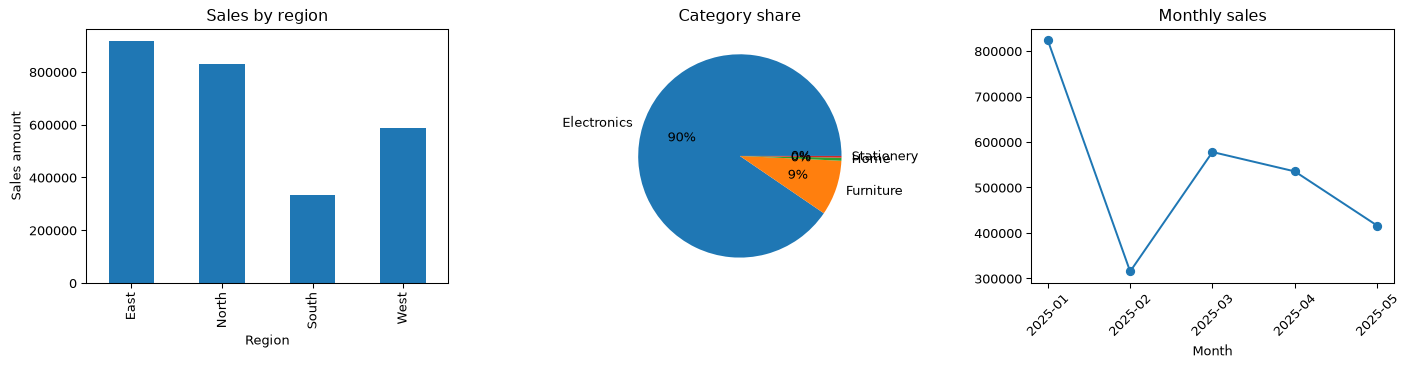

In [5]:
# Compare regions, categories and monthly trends visually.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sales.groupby("Region")["TotalSales"].sum().plot.bar(ax=axes[0], title="Sales by region")
sales.groupby("Category")["TotalSales"].sum().plot.pie(ax=axes[1], title="Category share", autopct="%1.0f%%")
axes[1].set_ylabel("")
sales.groupby("Month")["TotalSales"].sum().plot(ax=axes[2], marker="o", title="Monthly sales")
axes[0].set_ylabel("Sales amount")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
